# ADORA2A Retrospective Virtual Screening & Curation Audit

Walkthrough interactivo y reproducible de las cuatro fases del estudio sobre el receptor humano de adenosina $A_{2A}$ (`ADORA2A`, UniProt `P29274`, `CHEMBL251`):

1. **Auditoría estructural (GPCRdb + RCSB PDB):** por qué elegir `4EIY` (1.80 Å, bolsillo 100 % *wild-type*) frente a trampas de menor resolución nominal como `5NM4`/`5IU4` (`StaR2` con mutaciones `T88A` y `S277A` dentro del bolsillo).
2. **Curación de bioactividad y control de sesgo 1D:** separación estricta de cohortes ($K_i$ unión vs. $IC_{50}$ funcional), alertas estructurales con contexto farmacológico (p. ej. istradefilina) y auditoría *go/no-go* de decoys emparejados (incluyendo `TPSA`).
3. **Benchmark retrospectivo de 4 niveles y métricas honestas:** contraste cuantitativo entre *Accuracy* (~97.5 %) / ROC-AUC global y métricas de enriquecimiento temprano (**EF1%**, **EF5%**, **BEDROC $\alpha=20$**, **PR-AUC**), degradación por **Murcko scaffold split**, y demostración empírica de que **score de docking $\neq$ afinidad experimental ($pK_i$)**.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'
FIGS = ROOT / 'reports' / 'figures'

summary = json.loads((PROC / 'audit_summary.json').read_text(encoding='utf-8'))
print(f"Estructuras auditadas: {summary['n_structures_audited']}")
print('Distribución por estado:', summary['structures_by_state'])

Estructuras auditadas: 188
Distribución por estado: {'Inactive': 172, 'Active': 15, 'Intermediate': 1}


## 1. Fase 1 · Auditoría estructural (188 estructuras en PDB)

Inspeccionamos las estructuras inactivas de mayor resolución y comprobamos cómo las estructuras termoestabilizadas `StaR2` (`5NM4`, `5IU4`) mutan residuos polares clave del bolsillo ortostérico (`T88A`, `S277A`), mientras que `4EIY` (1.80 Å) conserva el bolsillo humano intacto.

,pdb_code,state,method,resolution,ligand_names,has_allosteric_na,mutation_count,construct_class
15,5NM4,Inactive,X-ray diffraction,1.70,ZM-241385,True,9,Thermostabilized StaR2 (pocket T88A/S277A risk)
16,5IU4,Inactive,X-ray diffraction,1.72,ZM-241385,True,11,Thermostabilized StaR2 (pocket T88A/S277A risk)
17,9H37,Inactive,X-ray diffraction,1.72,Compound 9,True,0,WT-7TM + ICL3-BRIL
18,9H2X,Inactive,X-ray diffraction,1.75,Compound 7,True,0,WT-7TM + ICL3-BRIL
19,4EIY,Inactive,X-ray diffraction,1.80,ZM-241385,True,3,WT-7TM + ICL3-BRIL
20,6LPJ,Inactive,X-ray diffraction,1.80,ZM-241385,True,3,WT-7TM + ICL3-BRIL
21,6LPK,Inactive,X-ray diffraction,1.80,ZM-241385,True,3,WT-7TM + ICL3-BRIL
22,7IO5,Inactive,X-ray diffraction,1.84,FU12-45; theophylline,True,8,Thermostabilized StaR2 (pocket T88A/S277A risk)


,pdb_code,state,method,resolution,ligand_names,has_allosteric_na,mutation_count,construct_class
0,2YDV,Active,X-ray diffraction,2.60,NECA,False,5,Thermostabilized GL31/StaR
1,4UG2,Active,X-ray diffraction,2.60,CGS 21680,False,5,Thermostabilized GL31/StaR
2,4UHR,Active,X-ray diffraction,2.60,CGS 21680,False,5,Thermostabilized GL31/StaR
3,5WF5,Active,X-ray diffraction,2.60,"UK-432,097",False,5,Thermostabilized GL31/StaR
4,9EE8,Active,Electron microscopy,2.63,adenosine,False,2,Active Gs/mini-Gs signaling complex
5,3QAK,Active,X-ray diffraction,2.71,"UK-432,097",False,2,WT-7TM + ICL3-T4L


Mutaciones detectadas en el bolsillo de 5IU4: {'88': ['THR', 'ALA'], '277': ['SER', 'ALA']}


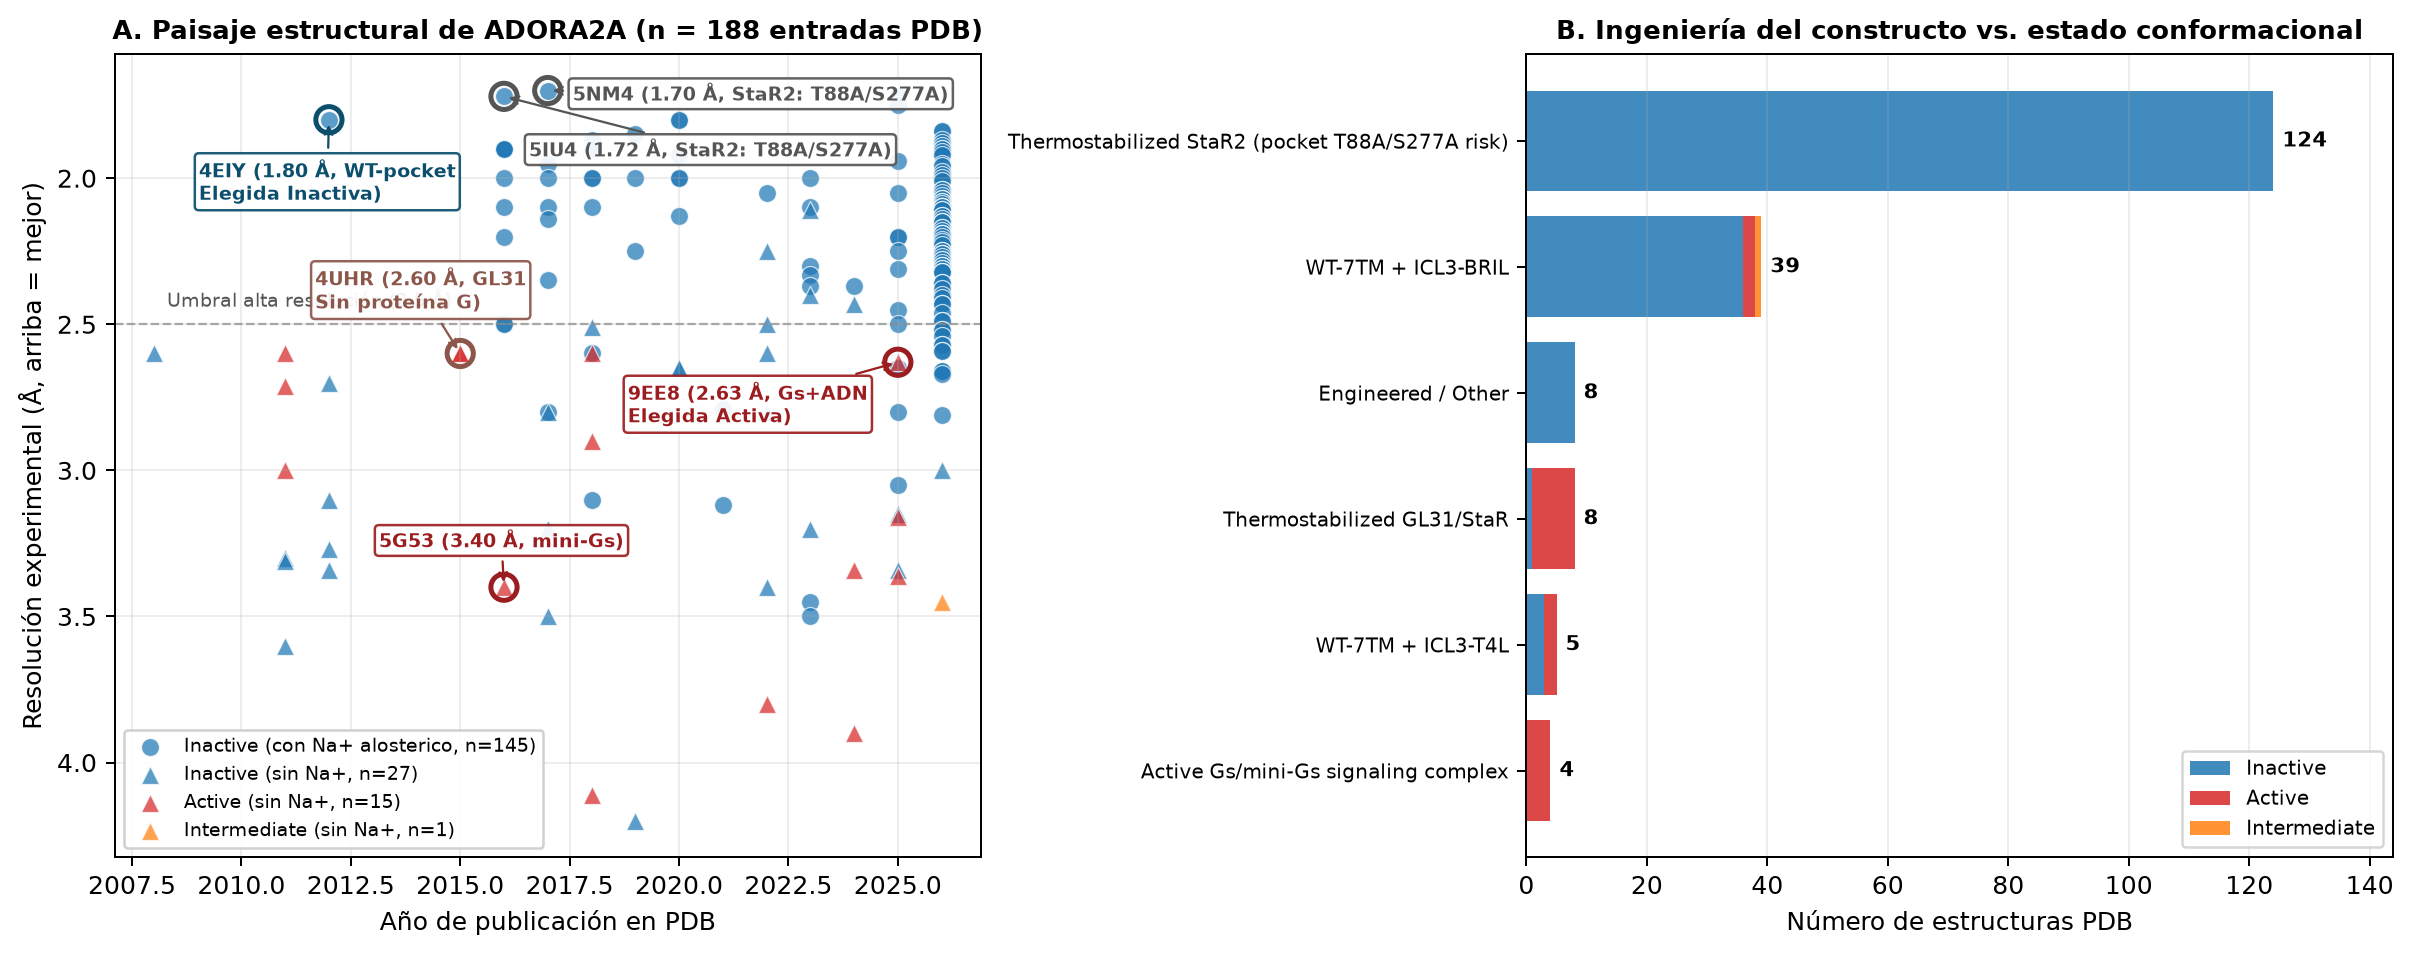

In [2]:
struct_df = pd.read_csv(PROC / 'adora2a_structures_audit.csv')
cols = ['pdb_code', 'state', 'method', 'resolution', 'ligand_names', 'has_allosteric_na', 'mutation_count', 'construct_class']
display(struct_df[struct_df['state'] == 'Inactive'].sort_values('resolution')[cols].head(8))
display(struct_df[struct_df['state'] == 'Active'].sort_values('resolution')[cols].head(6))
print('Mutaciones detectadas en el bolsillo de 5IU4:', summary['pocket_checks']['5IU4_mutations'])
display(Image(filename=str(FIGS / 'structure_audit_resolution_state.png')))

## 2. Fase 2 · Curación con procedencia, alertas con contexto y control de sesgo 1D

- **Cascada de curación:** filtramos `confidence_score >= 8`, relación exacta `'='`, unidades normalizadas a `nM`, y separamos estrictamente $K_i$ de unión (`Ki_B`) de $IC_{50}$.
- **Alertas PAINS/Brenk con criterio químico:** verificamos fármacos aprobados y sondas clínicas antes de aplicar filtros ciegos.
- **Puerta *Go/No-Go* del set de decoys:** un clasificador 1D (`LogisticRegression` y `RandomForest`) entrenado solo con `[MW, cLogP, TPSA, HBD, HBA, RotBonds, FormalCharge]` delata un sesgo severo en decoys aleatorios, pero cae por debajo de `0.60` tras el emparejamiento multivariante 7D.

,Paso de curación,Registros / Compuestos
0,01_raw_ki_ic50_records,12105
1,02_confidence_ge_8,12105
2,03_exact_relation_eq,8349
3,04_valid_nm_and_smiles,8347
4,05_no_validity_warning,8167
5,06_rdkit_standardized_organic,8150
6,07_cohort_Ki_B_measurements,5901
7,07b_cohort_IC50_B_measurements,1224
8,07c_cohort_IC50_F_measurements,496
9,08_unique_inchikey_Ki_B,4972


,name,clinical_status,has_pains,has_brenk,brenk_alerts
0,ZM241385,Preclinical gold-standard probe,False,False,NaN
1,Istradefylline,Approved (Phase 4),False,False,NaN
2,Caffeine,Approved (Phase 4),False,False,NaN
3,Theophylline,Approved (Phase 4),False,False,NaN
4,Preladenant,Phase 3,False,False,NaN
5,Vipadenant,Phase 2,False,True,aniline
6,Tozadenant,Phase 3,True,False,NaN
7,Imaradenant,Phase 2,False,True,2-halo_pyridine
8,Adenosine,Approved (Phase 4),False,False,NaN
9,NECA,Preclinical probe,False,False,NaN


Auditoría Go/No-Go de sesgo 1D: {
  "unmatched_logistic_auc": 0.8142,
  "unmatched_rf_auc": 0.7834,
  "matched_logistic_auc": 0.4841,
  "matched_rf_auc": 0.3464,
  "passed_go_nogo": true
}


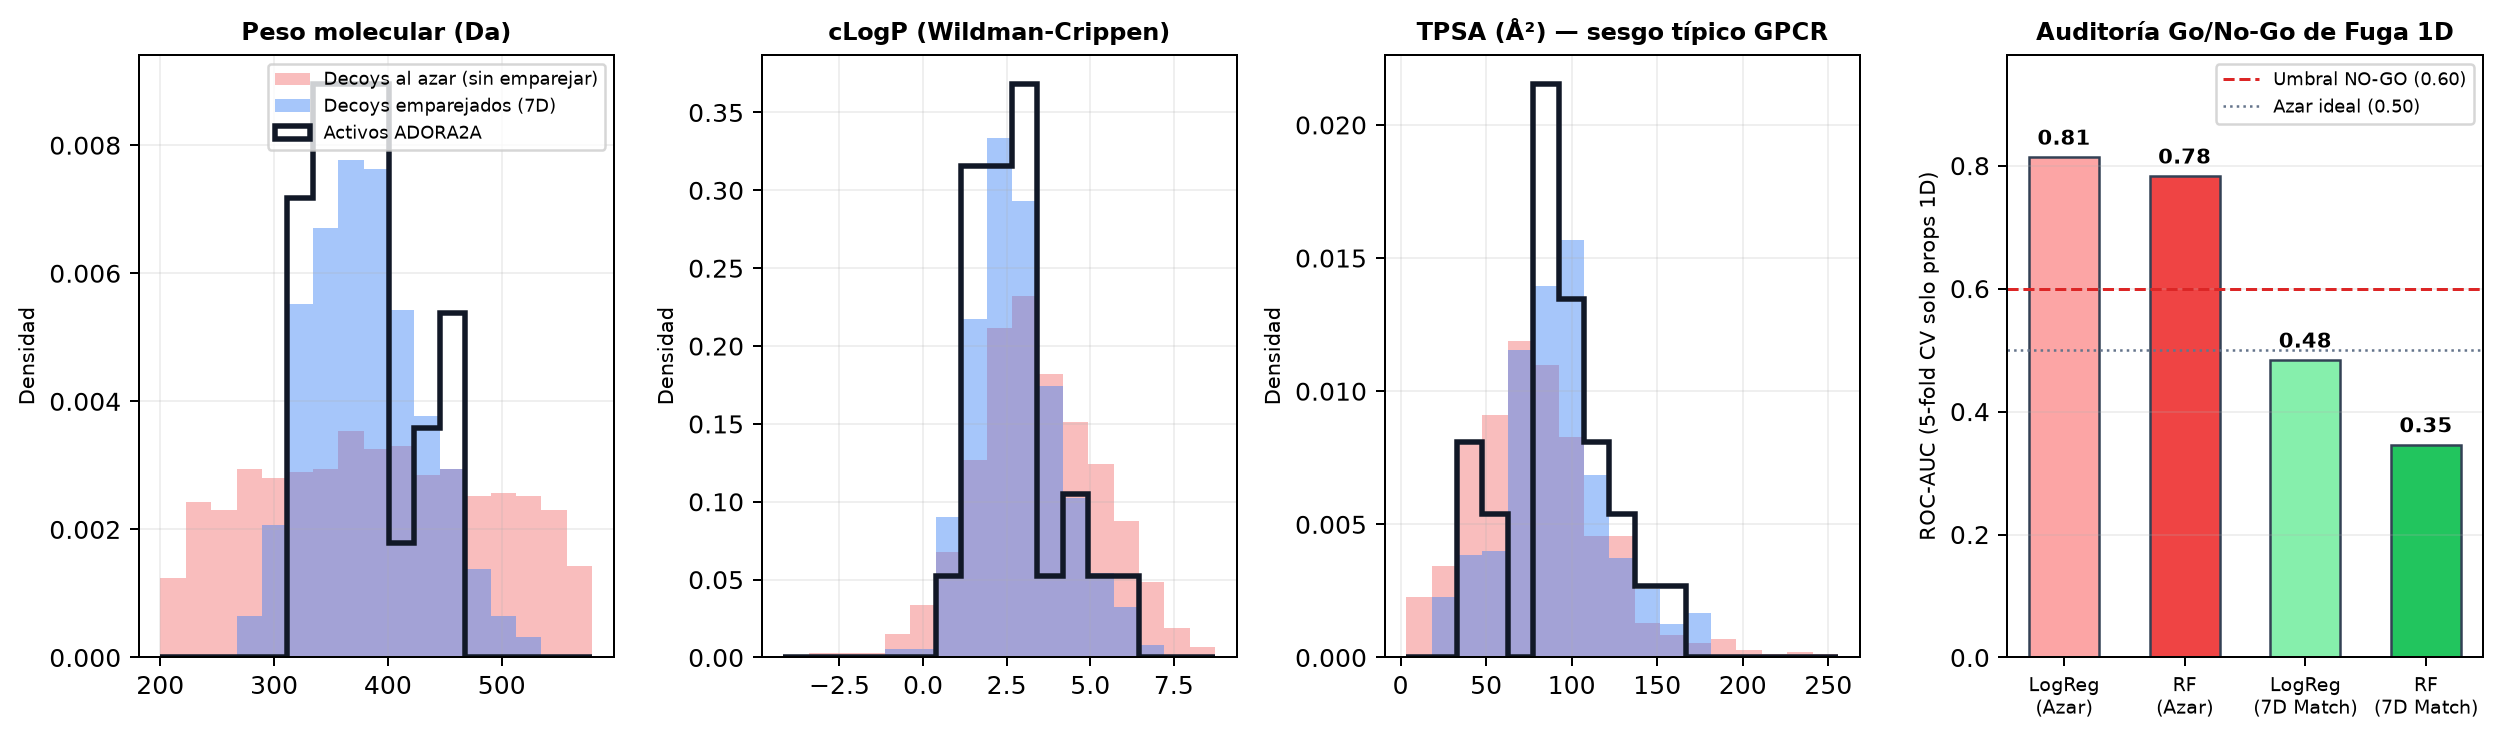

In [3]:
waterfall_df = pd.DataFrame(list(summary['curation_waterfall'].items()), columns=['Paso de curación', 'Registros / Compuestos'])
display(waterfall_df)

alerts_df = pd.read_csv(PROC / 'reference_ligands_alerts_audit.csv')
display(alerts_df[['name', 'clinical_status', 'has_pains', 'has_brenk', 'brenk_alerts']])

print('Auditoría Go/No-Go de sesgo 1D:', json.dumps(summary['bias_audit'], indent=2))
display(Image(filename=str(FIGS / 'decoy_property_matching_audit.png')))

## 3. Fase 3 · Benchmark retrospectivo de 4 niveles y métricas honestas

Comparamos sobre exactamente los mismos **1.000 compuestos** (25 activos diversos + 975 decoys emparejados en 7D, tasa de hits del **2,5 %**):
1. **Control negativo 1D** (Random Forest OOF sobre propiedades fisicoquímicas).
2. **Similitud 2D ECFP4** frente al ligando co-cristalizado `ZM241385` (más auditoría sin análogos cercanos y **Murcko scaffold split** experimental).
3. **Forma y farmacóforo 3D** (`ETKDGv3` + `USRCAT` + `CrippenO3A Shape Tanimoto` frente a `ZMA`).
4. **Docking basado en estructura** (**AutoDock Vina v1.2.7** sobre el bolsillo *wild-type* de `4EIY` a pH 7,4).

,method,ef1,ef5,bedroc_20,roc_auc,pr_auc,accuracy_top1pct,naive_all_inactive_accuracy
0,1D Fisicoquímico (Control),0.0,0.0,0.026,0.346,0.019,0.965,0.975
1,2D ECFP4 (vs ZM241385),36.0,9.6,0.519,0.725,0.433,0.983,0.975
2,3D Forma + USRCAT (vs ZMA),8.0,6.4,0.355,0.722,0.166,0.969,0.975
3,3D Docking (AutoDock Vina · 4EIY),0.0,0.8,0.063,0.584,0.033,0.965,0.975



Subconjunto estricto de salto de andamio (excluyendo análogos con ECFP4 >= 0.35 a ZM241385):


,method,n_actives,ef1,ef5,bedroc_20,roc_auc,pr_auc
0,"2D ECFP4 (sin análogos ZMA, ECFP4<0.35)",21,23.714,7.589,0.402,0.673,0.303
1,"AutoDock Vina (sin análogos ZMA, ECFP4<0.35)",21,0.000,0.949,0.072,0.625,0.032



Generalización supervisada 2D en CHEMBL251 experimental (Random Split vs Murcko Scaffold Split):


,method,ef1,ef5,bedroc_20,roc_auc,pr_auc
0,2D ECFP4 ML experimental (Random Split),8.142,8.239,0.947,0.983,0.917
1,2D ECFP4 ML experimental (Murcko Scaffold Split),8.142,7.827,0.914,0.979,0.880


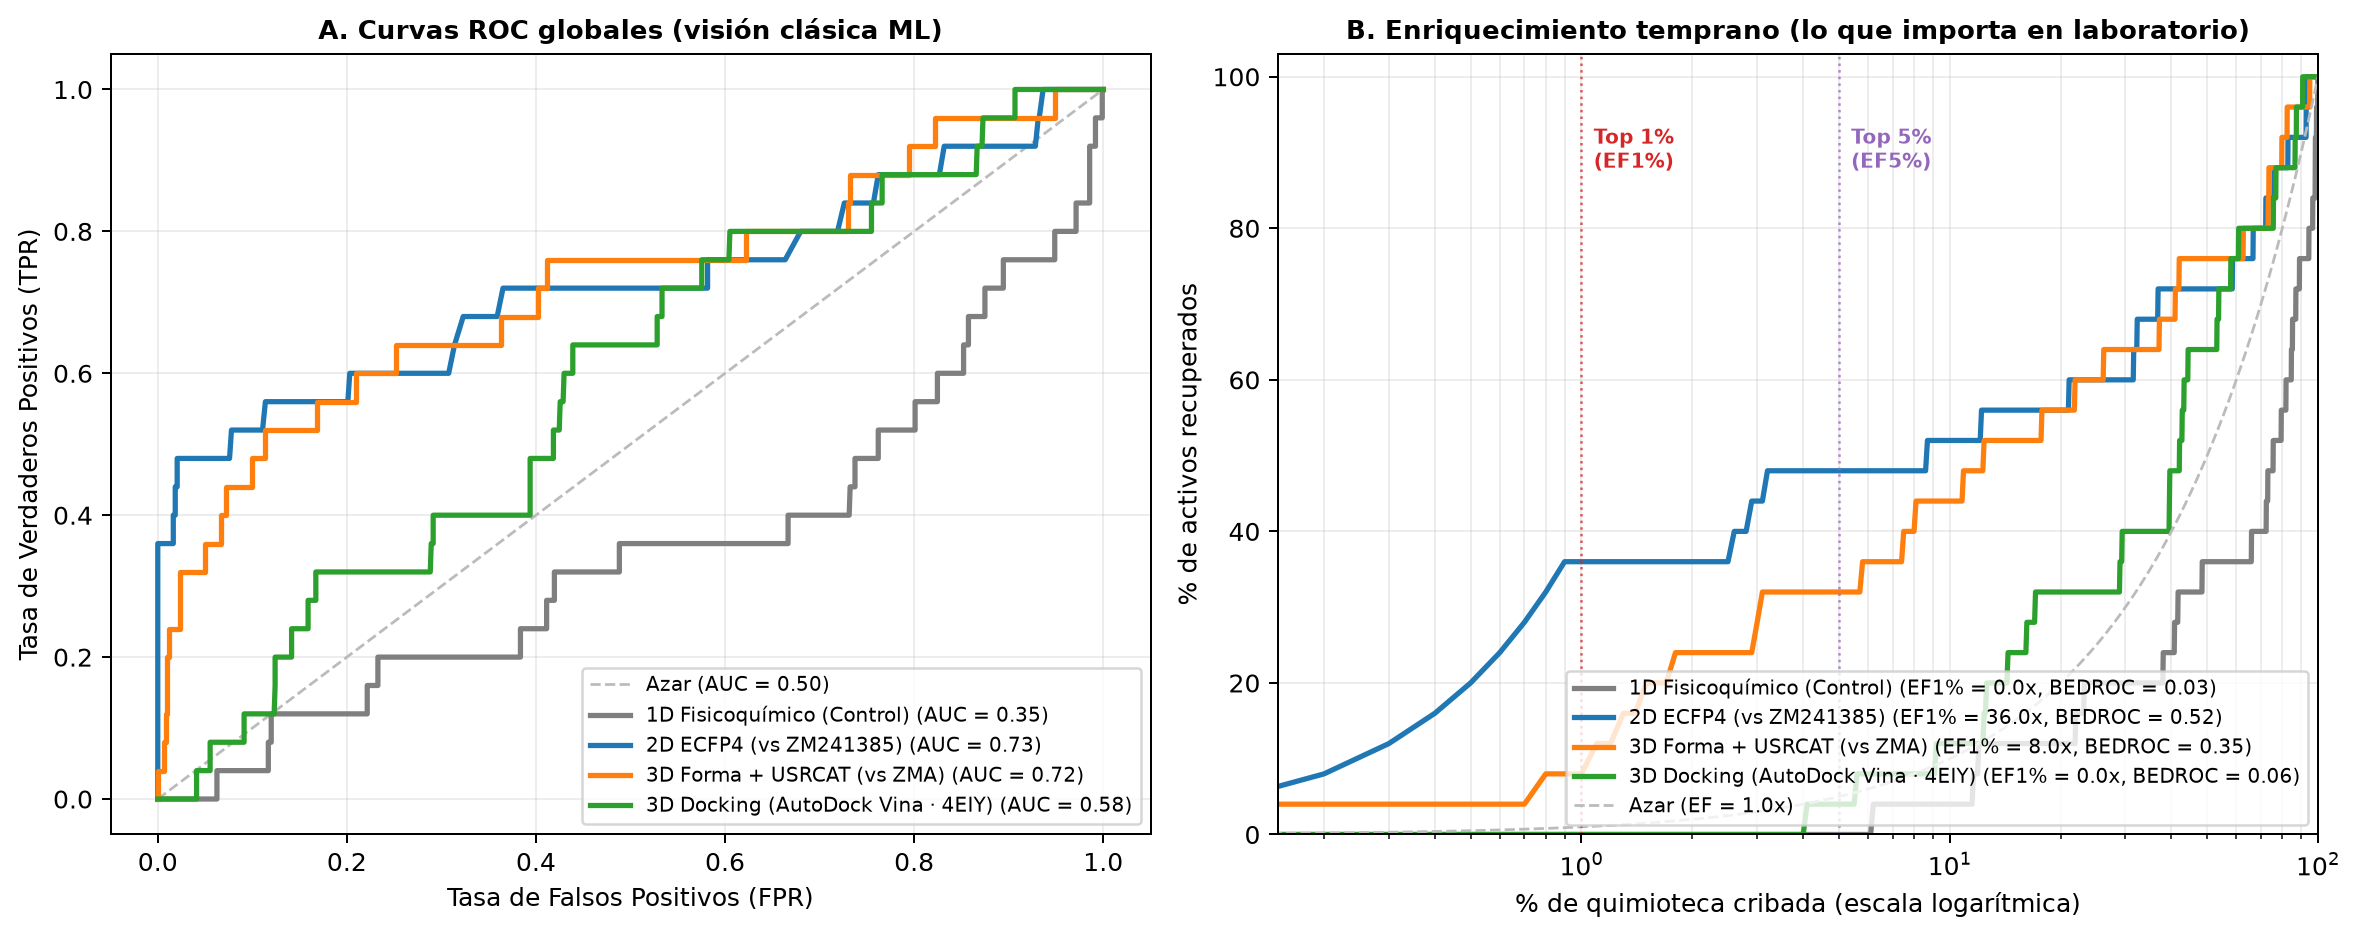

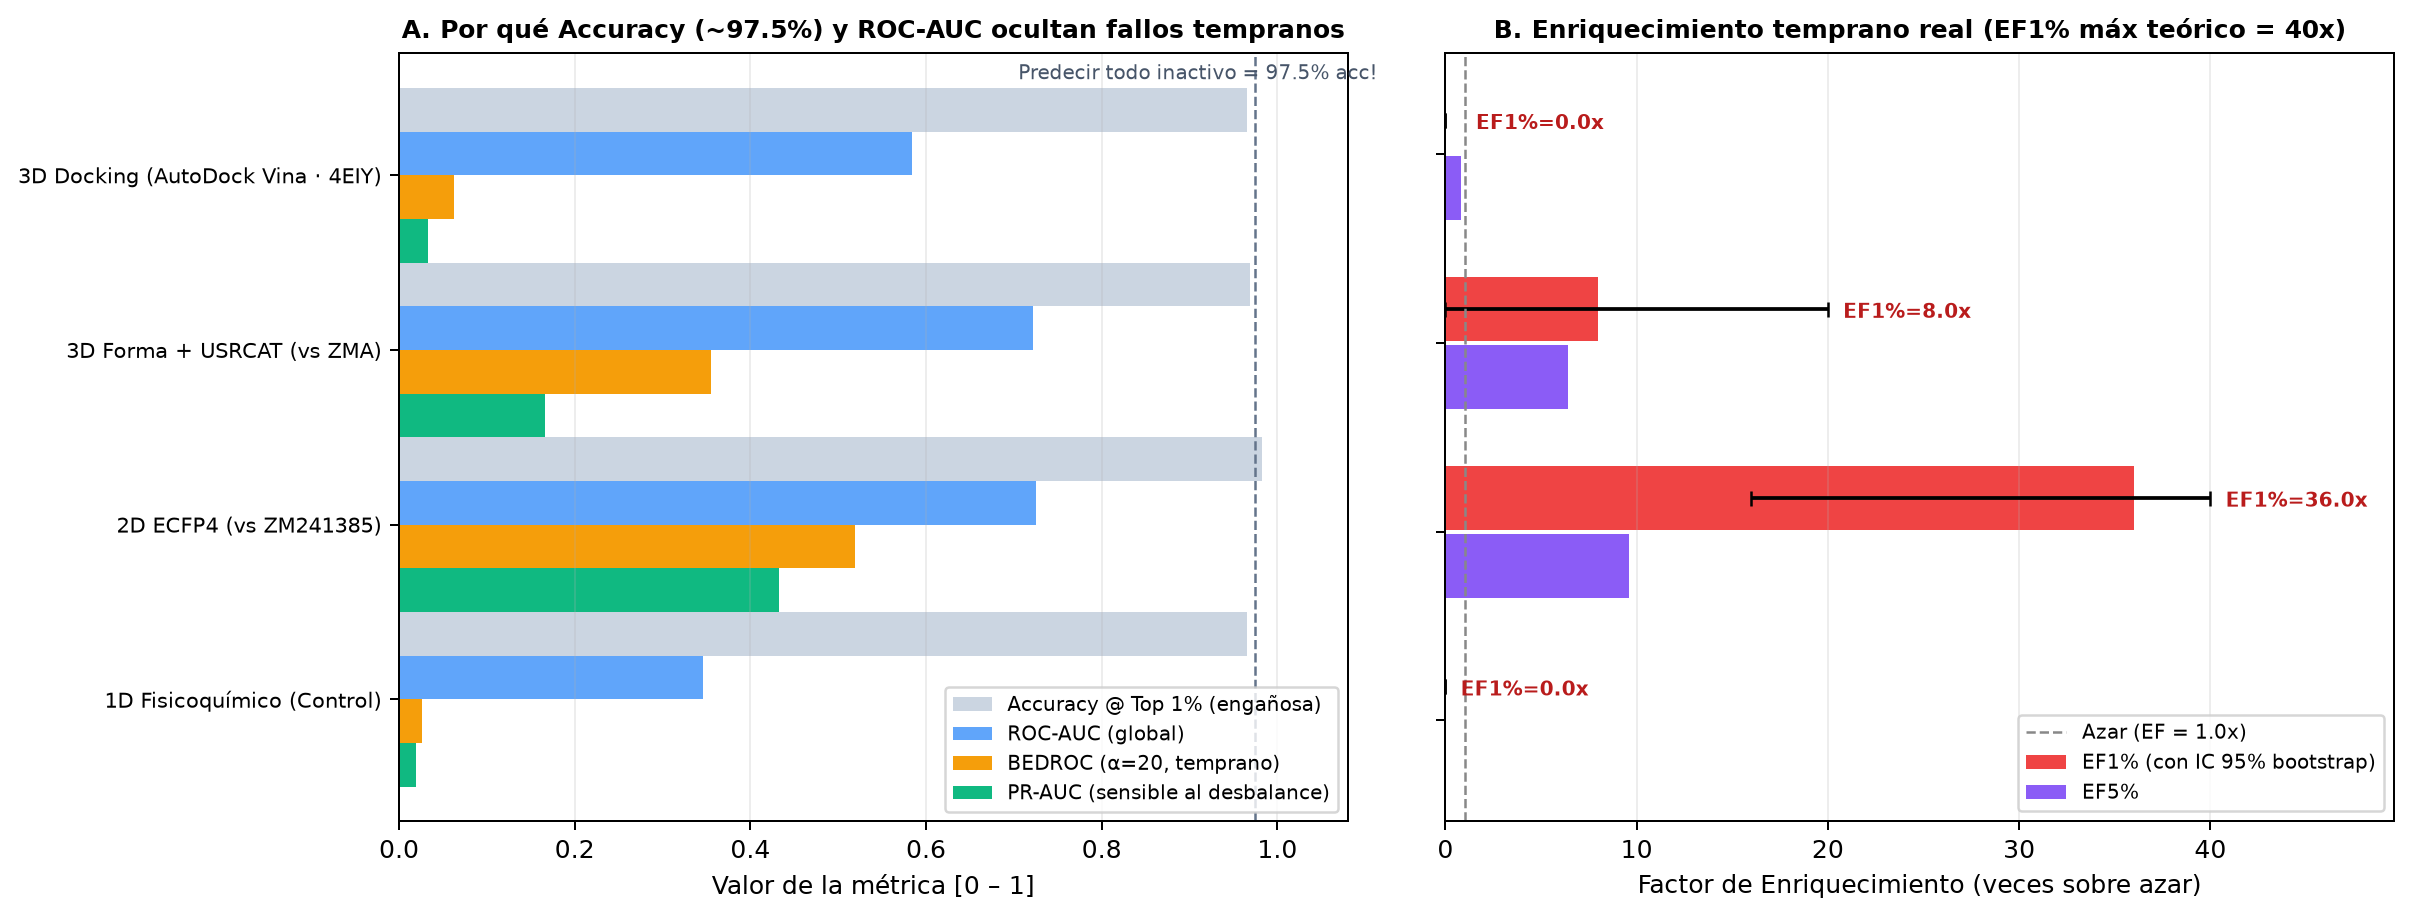

In [4]:
metrics_df = pd.DataFrame(summary['benchmark_metrics'])
display(metrics_df[['method', 'ef1', 'ef5', 'bedroc_20', 'roc_auc', 'pr_auc', 'accuracy_top1pct', 'naive_all_inactive_accuracy']].round(3))

print('\nSubconjunto estricto de salto de andamio (excluyendo análogos con ECFP4 >= 0.35 a ZM241385):')
hop = summary['scaffold_hop_no_zma_analogues']
display(pd.DataFrame([hop['2d_ecfp4'], hop['autodock_vina']])[['method', 'n_actives', 'ef1', 'ef5', 'bedroc_20', 'roc_auc', 'pr_auc']].round(3))

print('\nGeneralización supervisada 2D en CHEMBL251 experimental (Random Split vs Murcko Scaffold Split):')
ms = summary['murcko_split_experimental_chembl']
display(pd.DataFrame([ms['random_split'], ms['murcko_scaffold_split']])[['method', 'ef1', 'ef5', 'bedroc_20', 'roc_auc', 'pr_auc']].round(3))

display(Image(filename=str(FIGS / 'benchmark_roc_and_enrichment.png')))
display(Image(filename=str(FIGS / 'metrics_accuracy_vs_enrichment.png')))

## 4. Correlación Score vs. Afinidad Experimental ($pK_i$)

Evaluamos 60 ligandos de `CHEMBL251` con $K_i$ experimental de equilibrio a lo largo de ~5 órdenes de magnitud ($pK_i \in [4.8, 9.8]$, desde metilxantinas micromolares como cafeína/teofilina hasta antagonistas sub-nanomolares), cuantificando Pearson $r$, $R^2$ y Spearman $\rho$.

,pearson_r,pearson_r2,pearson_p,spearman_rho,spearman_p
"AutoDock Vina (-ΔG, kcal/mol)",0.161,0.026,0.2186,0.222,0.0888
2D ECFP4 Tanimoto (vs ZM241385),0.246,0.060,0.0583,0.226,0.0826
3D Shape + USRCAT (vs ZM241385),0.524,0.274,0.0000,0.500,0.0000


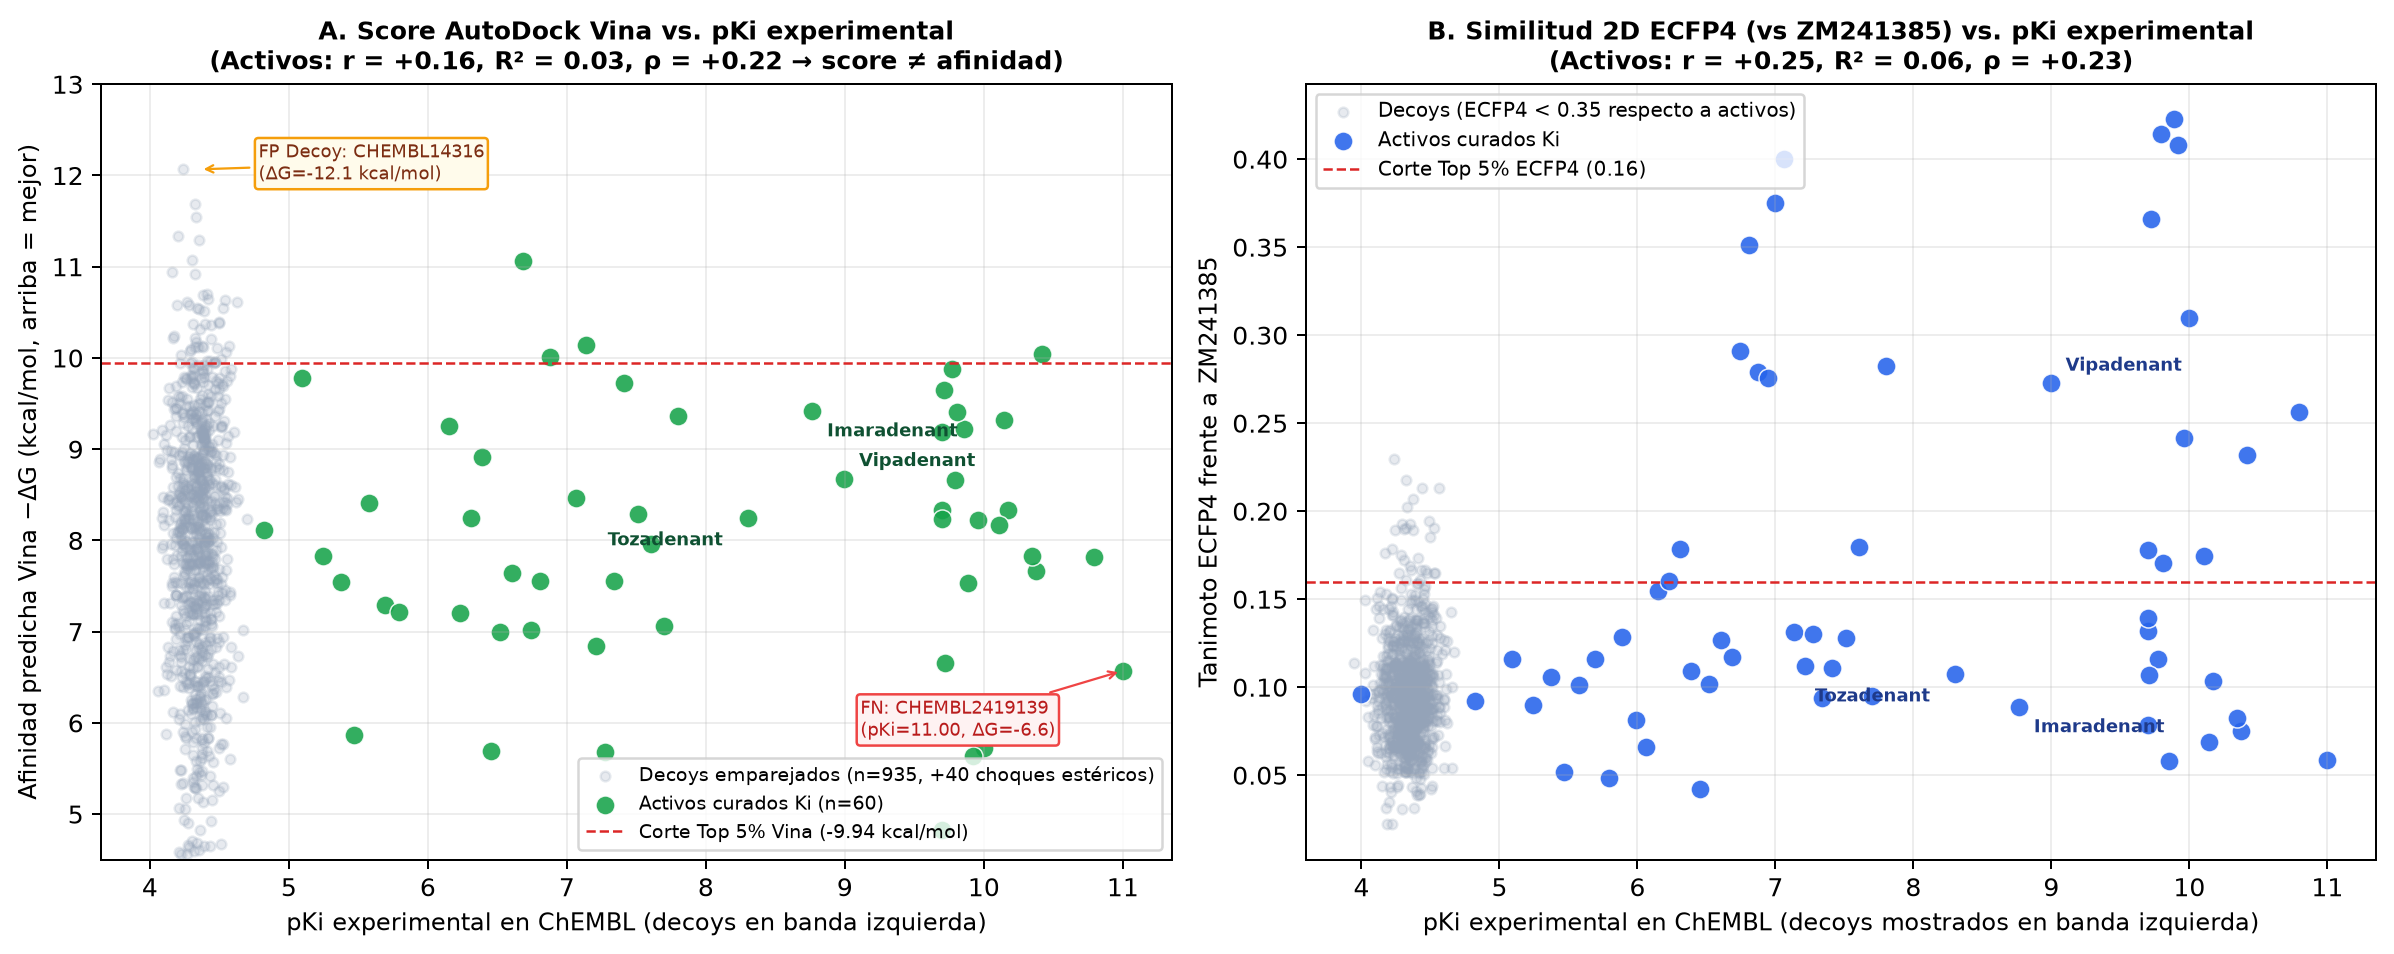

In [5]:
corr_df = pd.DataFrame(summary['affinity_correlation_wide_n60']).T
display(corr_df)
display(Image(filename=str(FIGS / 'affinity_vs_score_scatter.png')))